# GH-II model

After trying `test-0-x`, now, we proceed to propose canonical toy models for the paper and test basic properties, preparing for scanning.

`test-2-x` are for the GH-II model, which is more like `GLU`.

In this model, the input $x\in \mathbb{R}^m$. We have a key matrix $K \in \mathbb{R}^{d\times m}$, a gate matrix $G \in \mathbb{R}^{d \times m}$, and a value tensor $V \in \mathbb{R}^{m \times d}$. The output of the gate is computed as:
$$
h =  V(Gx \odot Kx).
$$
We call this part G-II, gate model type II.
After the gate, we project the hidden state out with a head $W \in \mathbb{R}^{n\times m}$, and the final logits is:
$$
y = Wh \in \mathbb{R}^n.
$$

Visually, one can see
<img src="GHmodels.jpeg" alt="GHmodels" width="600">

We want the toy model to have the following properties:
- 1/3 scaling for gate part
- 3/4 situations of GH can show the 1/3 scaling, 1/4 situation means both high temperature.
- Maybe increasing Hessian, not necessary.

This notebook is for GH-II model with low-temperature gate and high-temperature head. `Tanh`!

In [1]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from dataclasses import dataclass
import matplotlib.pyplot as plt

In [2]:
# ---- Config ----
@dataclass
class Config:
    vocab_size: int = 128     # vocab size (n)
    n_embd: int = 32         # model width (m)
    beta: float = 1.0              # scaling factor for the logits
    beta_g: float = 1.0            # scaling factor for the gating
    teacher: bool = False             # whether to use teacher model
    d_h: int = 96             # hidden dimension in gate

# ---- Utils ----
def rmsnorm(x: torch.Tensor):
    return F.rms_norm(x, (x.size(-1),))

# ---- Model ----
class GATE_II(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        if cfg.teacher:
            self.K = torch.nn.Parameter(torch.randn(cfg.d_h, cfg.n_embd)/ (cfg.n_embd ** 0.5))
            self.G = torch.nn.Parameter(torch.randn(cfg.d_h, cfg.n_embd) * cfg.beta_g / (cfg.n_embd ** 0.5))
            self.V = torch.nn.Parameter(torch.randn(cfg.n_embd, cfg.d_h) / (cfg.d_h ** 0.5))
        else:
            self.K = torch.nn.Parameter(torch.randn(cfg.d_h, cfg.n_embd)/ (cfg.n_embd ** 0.5))
            self.G = torch.nn.Parameter(torch.zeros(cfg.d_h, cfg.n_embd))
            self.V = torch.nn.Parameter(torch.zeros(cfg.n_embd, cfg.d_h))

    def forward(self, x: torch.Tensor):
        # x: (batch_size, n_embd)
        keys = F.linear(x, self.K)  # (batch_size, d_h)
        gates = F.tanh(F.linear(x, self.G))  # (batch_size, d_h)
        keys = keys * gates  # (batch_size, d_h)
        out = F.linear(keys, self.V)  # (batch_size, n_embd)
        return out

class GH_II(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.gate = GATE_II(cfg)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        if cfg.teacher:
            self.head.weight.data.copy_(torch.randn(cfg.vocab_size, cfg.n_embd) / (cfg.n_embd ** 0.5))
        else:
            self.head.weight.data.zero_()
            
    def forward(self, x: torch.Tensor):
        # x: (batch_size, n_embd)
        x = rmsnorm(x)
        x = self.gate(x) + x  # residual connection
        x = rmsnorm(x)
        logits = self.head(x) * self.cfg.beta  # scale logits
        return logits

In [3]:
t_cfg = Config(beta = 1.0, beta_g = 1000.0, teacher = True)
teacher = GH_II(t_cfg)
s_cfg = Config()
student = GH_II(s_cfg)
with torch.no_grad(): # not necessary, but can reach the 1/3 region faster, good for debugging and testing, where only do 2000 steps.
    student.gate.K.copy_(teacher.gate.K + torch.randn_like(teacher.gate.K) * 0.1)
    student.gate.V.copy_(teacher.gate.V + torch.randn_like(teacher.gate.V) * 0.1)

init_K = student.gate.K.detach().clone()
init_V = student.gate.V.detach().clone()
batch_size = 2048
base_lr = 10

optimizer = torch.optim.SGD([{'params': [student.gate.K, student.gate.V], 'lr': base_lr},
                               {'params': [student.gate.G], 'lr': base_lr},
                               {'params': student.head.parameters(), 'lr': base_lr}])

losses = []
#s_logits_stds = []
#t_logits_stds = []
#entropies = []
#t_entropies = []
s_beta_G = []
K_diff = []
V_diff = []

num_steps = 2000 # 18s
for step in range(num_steps):
    x = torch.randn(batch_size, s_cfg.n_embd)
    with torch.no_grad():
        teacher_logits = teacher(x)
        teacher_log_probs = F.log_softmax(teacher_logits, dim=-1)
    student_logits = student(x)
    student_log_probs = F.log_softmax(student_logits, dim=-1)
    loss = F.kl_div(student_log_probs, teacher_log_probs, reduction='batchmean', log_target=True)
    #loss = F.mse_loss(student_logits, teacher_logits)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    s_beta_G.append(student.gate.G.norm().item() / (s_cfg.d_h ** 0.5))
    K_diff.append((student.gate.K - init_K).norm().item())
    V_diff.append((student.gate.V - init_V).norm().item())

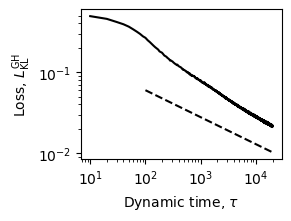

In [9]:
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
plt.plot(torch.arange(1, len(losses) + 1)*base_lr, losses, 'k')
plt.plot([100, 20000], [.06, .06/200**(1/3)], 'k--')
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Loss, $L_{\rm KL}^{\rm GH}$")
plt.xscale('log')
plt.yscale('log')
plt.savefig("../../figures/GHIIlossTanh.pdf")

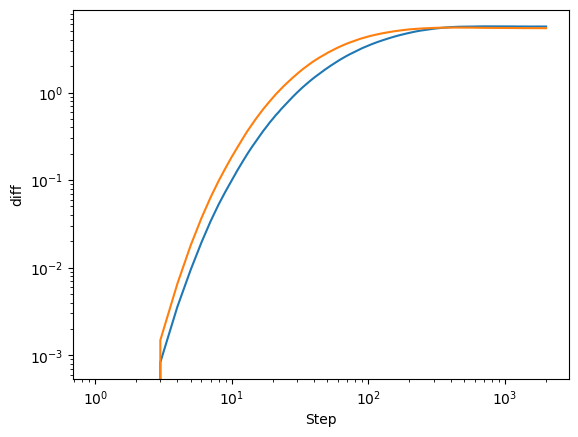

In [5]:
plt.plot(range(1, len(losses) + 1), K_diff)
plt.plot(range(1, len(losses) + 1), V_diff)
plt.xlabel('Step')
plt.ylabel('diff')
plt.xscale('log')
plt.yscale('log')

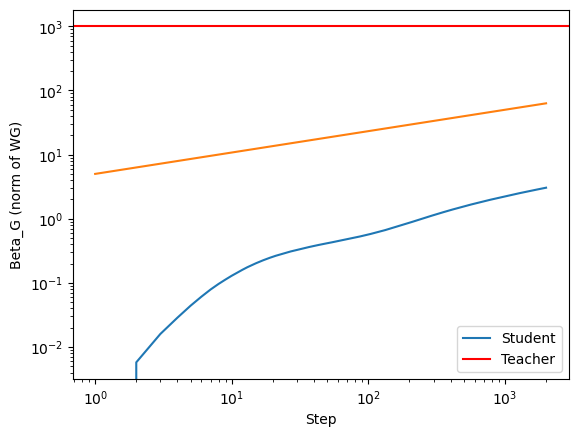

In [6]:
plt.plot(range(1, len(losses) + 1), s_beta_G, label='Student')
plt.axhline(t_cfg.beta_g, label='Teacher', color='red')
plt.plot([1,2000], [5, 5 * 2000 ** (1/3)])
plt.xlabel('Step')
plt.ylabel('Beta_G (norm of WG)')
plt.xscale('log')
plt.yscale('log')
plt.legend()

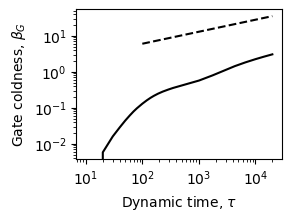

In [10]:
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
plt.plot(torch.arange(1, len(losses) + 1)*base_lr, s_beta_G, 'k')
plt.plot([100, 20000], [6, 6*200**(1/3)], 'k--')
plt.xlabel(r"Dynamic time, $\tau$")
plt.ylabel(r"Gate coldness, $\beta_G$")
plt.xscale('log')
plt.yscale('log')
plt.savefig("../../figures/GHIIcoldnessTanh.pdf")